# Практикум. Как из сырых таблиц получить выводы

**Задача.** У нас есть данные об испытаниях стали, разложенные по трём файлам:

- в первом записаны образцы и их свойства (прочность, твёрдость и др.),
- во втором записаны партии стали (кто поставил, когда плавили),
- в третьем записаны поставщики (город, рейтинг).

Мы соберём всё в одну таблицу и шаг за шагом разберёмся:

1. какие значения типичные, а какие сильно отличаются от остальных,
2. похожи ли данные на «нормальное» распределение и зачем это знать,
3. есть ли ошибки в данных и что с ними делать,
4. как нарисовать понятные графики,
5. какие группы образцов можно сравнивать между собой.

**Как работать.** Запускайте ячейки по очереди сверху вниз: Shift + Enter. После каждого результата читайте пояснение под ним. В ячейках со значком ✏️ код пишете вы сами.

**Про данные.** Набор `stal_partii.csv` придуман для учёбы, это не измерения настоящего завода. В него специально добавлены пропуски и одна ошибка, чтобы было что искать.

## 0. Подготовка

### Если вы работаете в Google Colab

1. Откройте сайт colab.research.google.com, выберите «Файл → Загрузить блокнот» и укажите этот файл `.ipynb`.
2. Файлы с данными лежат в той же папке, что и этот ноутбук (`1_практикум`). Нужны три файла: `stal_partii.csv`, `партии.csv`, `поставщики.csv`.
3. Запустите ячейку ниже. Появится кнопка «Выбрать файлы». Выберите все три файла сразу (удерживайте Ctrl, на Mac — Cmd).

Colab хранит загруженные файлы только до конца работы. Если вы закрыли вкладку или долго не работали, загрузите файлы ещё раз.

### Если вы работаете в Jupyter на своём компьютере

Ячейку ниже пропустите. Просто положите три файла в ту же папку, где лежит этот ноутбук.

Теперь подключим библиотеки. Библиотека это готовый набор команд, который написали другие люди. В Colab все нужные библиотеки уже есть.

- `pandas` работает с таблицами,
- `numpy` считает,
- `scipy.stats` проверяет статистические гипотезы,
- `matplotlib` и `seaborn` рисуют графики.

In [2]:
# import подключает библиотеку, as даёт ей короткое имя (так принято во всём мире)
import numpy as np                # вычисления с числами и массивами
import pandas as pd               # таблицы (DataFrame)
import matplotlib.pyplot as plt   # базовая библиотека графиков
import seaborn as sns             # красивые статистические графики поверх matplotlib
from scipy import stats           # статистические критерии (Шапиро–Уилк, корреляции и др.)

# настройки внешнего вида, чтобы у всех получалось одинаково
pd.set_option('display.precision', 2)              # показывать в таблицах 2 знака после запятой
sns.set_theme(style='whitegrid', font_scale=1.05)  # белый фон с сеткой, шрифт чуть крупнее
plt.rcParams['figure.figsize'] = (8, 4.5)          # размер графиков по умолчанию: ширина 8, высота 4,5 дюйма

## 1. Загружаем таблицы и смотрим на них

Прежде чем что-то считать, на каждую таблицу нужно просто посмотреть. Ответьте себе на четыре вопроса:

1. Сколько в ней строк и столбцов?
2. Что записано в одной строке: один образец? одна партия?
3. Где числа, а где текст?
4. Есть ли пустые клетки?

In [3]:
# pd.read_csv читает CSV-файл (таблицу, где значения разделены запятыми) и возвращает DataFrame
сталь = pd.read_csv('stal_partii.csv')
партии = pd.read_csv('партии.csv')
поставщики = pd.read_csv('поставщики.csv')

# .shape — размер таблицы: (число строк, число столбцов)
print('сталь:', сталь.shape, '  партии:', партии.shape, '  поставщики:', поставщики.shape)

# .head() показывает первые 5 строк — быстрый способ посмотреть, как устроена таблица
сталь.head()

сталь: (90, 6)   партии: (4, 4)   поставщики: (4, 3)


,образец,партия,прочность,твёрдость,углерод,плотность
0,П-1-01,П-1,493.2,204.3,0.14,7.88
1,П-1-02,П-1,477.1,181.3,0.20,7.86
2,П-1-03,П-1,512.3,180.4,0.23,7.85
3,П-1-04,П-1,518.2,177.7,0.25,7.86
4,П-1-05,П-1,467.0,NaN,0.26,7.81


In [4]:
# если в последней строке ячейки написать просто имя таблицы, Jupyter покажет её целиком
партии

,партия,поставщик,дата_плавки,углерод
0,П-1,Магнитка,2026-03-04,0.21
1,П-2,Северсталь,2026-03-11,0.27
2,П-3,Магнитка,2026-04-02,0.38
3,П-4,НЛМК,2026-04-18,0.24


In [5]:
# справочник поставщиков: всего 4 строки, смотрим целиком
поставщики

,поставщик,город,рейтинг
0,Магнитка,Магнитогорск,4.6
1,Северсталь,Череповец,4.8
2,НЛМК,Липецк,4.5
3,Мечел,Челябинск,4.1


**Что мы видим.**

- В таблице `сталь` одна строка это **один образец**. В столбце `партия` написано, из какой он партии.
- В таблице `партии` одна строка это **одна партия**: кто её поставил и когда плавили.
- В таблице `поставщики` одна строка это **один поставщик**: город и рейтинг.

Таблицы связаны цепочкой: образец → партия → поставщик. Столбец, через который таблицы связаны, называют **ключом**. Это как номер заказа, по которому магазин находит и покупателя, и товар.

**Внимание:** столбец `углерод` есть в двух таблицах, но значит он разное. В `сталь` это углерод, измеренный в конкретном образце. В `партии` это углерод, указанный в документах на всю плавку. Путать их нельзя.

In [6]:
# .info() — паспорт таблицы: имена столбцов, сколько в каждом непустых значений (Non-Null Count)
# и тип данных (Dtype): float64 — дробные числа, int64 — целые, object — текст
сталь.info()

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   образец    90 non-null     str    
 1   партия     90 non-null     str    
 2   прочность  90 non-null     float64
 3   твёрдость  88 non-null     float64
 4   углерод    89 non-null     float64
 5   плотность  88 non-null     float64
dtypes: float64(4), str(2)
memory usage: 4.3 KB


Команда `info()` показала, что в столбцах `твёрдость`, `углерод` и `плотность` меньше 90 значений. Значит, там есть пустые клетки, то есть **пропуски**. В pandas пропуск выглядит как `NaN` (от английского «не число»).

**Зачем считать пропуски.**

1. **Чтобы знать, сколько данных на самом деле.** Если из 90 образцов у 30 не измерили твёрдость, то о твёрдости мы знаем только по 60 образцам.
2. **Чтобы решить, что с ними делать.** Если пропусков мало, их можно просто не учитывать. Если пропусков много, такому столбцу трудно доверять.
3. **Чтобы проверить, нет ли перекоса.** Если все пропуски попали в одну партию (например, в тот день сломался прибор), то эту партию мы знаем хуже других, и сравнение будет нечестным.
4. **Чтобы не получить пустой ответ.** Некоторые команды не умеют работать с пропусками. Например, проверка Шапиро–Уилка вместо ответа выдаст `nan`. Поэтому дальше мы будем писать `.dropna()`, что значит «сначала убери пропуски».

Посчитаем пропуски и посмотрим, в каких они строках.

In [7]:
# .isna() ставит True там, где значение пропущено, .sum() считает True в каждом столбце
print(сталь.isna().sum())

# .any(axis=1) проверяет каждую строку: есть ли в ней хотя бы один пропуск
# таблица[условие] оставляет только строки, где условие True
сталь[сталь.isna().any(axis=1)]

образец      0
партия       0
прочность    0
твёрдость    2
углерод      1
плотность    2
dtype: int64


,образец,партия,прочность,твёрдость,углерод,плотность
4,П-1-05,П-1,467.0,NaN,0.26,7.81
12,П-1-13,П-1,493.5,179.0,NaN,7.85
37,П-2-08,П-2,480.9,NaN,0.20,7.90
55,П-2-26,П-2,501.9,191.6,0.26,NaN
71,П-3-12,П-3,568.7,189.3,0.40,NaN


Пропусков всего 5, и все они в разных строках. Удалять такие строки целиком **не будем**. Если у образца не измерили плотность, его прочность от этого не стала неправильной. Каждый показатель посчитаем по тем образцам, где он есть. pandas так и делает сам: при расчёте среднего пропуски просто пропускаются.

## 2. Склеиваем таблицы

### 2.1. Сначала проверяем ключи

При склеивании таблиц чаще всего случаются две ошибки:

- в справочнике один и тот же ключ записан дважды, и тогда строки размножаются,
- ключ записан по-разному (например, «П-3» и « П-3» с пробелом), и строки не находят пару.

Поэтому ключи проверяем **до** склеивания.

Заодно исправим названия поставщиков. В файлах записано разговорное «Магнитка» и сокращение «НЛМК». В отчёте и на графиках должны стоять полные названия. Менять их нужно **в обеих таблицах одинаково**, иначе ключи перестанут совпадать.

In [8]:
# .str.strip() убирает пробелы в начале и в конце текста: ' П-3' превратится в 'П-3'
# для компьютера 'П-3' и ' П-3' — разные ключи, и строки не найдут пару
for т in [сталь, партии]:
    т['партия'] = т['партия'].str.strip()
партии['поставщик'] = партии['поставщик'].str.strip()
поставщики['поставщик'] = поставщики['поставщик'].str.strip()

# .unique() — список разных значений столбца, sorted() упорядочивает его
# в справочниках поставщики записаны сокращённо, заменим сокращения на полные названия
# .replace({старое: новое}) меняет значения по словарю, остальные значения не трогает
полные_названия = {
    'Магнитка': 'Магнитогорский металлургический комбинат',
    'НЛМК': 'Новолипецкий металлургический комбинат',
}
партии['поставщик'] = партии['поставщик'].replace(полные_названия)
поставщики['поставщик'] = поставщики['поставщик'].replace(полные_названия)

print('Партии в образцах:   ', sorted(сталь['партия'].unique()))
print('Партии в справочнике:', sorted(партии['партия'].unique()))

# .is_unique отвечает True, если ни одно значение в столбце не повторяется
print('Ключ партии уникален в справочнике партий:', партии['партия'].is_unique)
print('Ключ поставщика уникален в справочнике:  ', поставщики['поставщик'].is_unique)

Партии в образцах:    ['П-1', 'П-2', 'П-3']
Партии в справочнике: ['П-1', 'П-2', 'П-3', 'П-4']
Ключ партии уникален в справочнике партий: True
Ключ поставщика уникален в справочнике:   True


**Что мы видим.**

- Все три партии из таблицы образцов (П-1, П-2, П-3) есть в справочнике партий. Значит, каждый образец найдёт свою партию.
- В справочнике есть ещё партия П-4, но образцов из неё у нас нет.
- В справочниках ключи не повторяются, поэтому строки при склеивании не размножатся.

Такая связь называется **«многие к одному»**: много образцов относятся к одной партии.

### 2.2. Как склеивать

Команда `merge` склеивает таблицы. Главный вопрос: что делать со строками, которым не нашлась пара. За это отвечает параметр `how`:

| how | что останется в результате | что будет с партией П-4 |
|---|---|---|
| `inner` | только строки, у которых нашлась пара | исчезнет |
| `left` | все строки левой (первой) таблицы | исчезнет |
| `right` | все строки правой (второй) таблицы | останется пустой строкой |
| `outer` | все строки из обеих таблиц | останется пустой строкой |

Мы изучаем образцы, поэтому нам нужны **все образцы**, и к каждому сведения о его партии. Значит, берём `how='left'`, а левой таблицей ставим `сталь`. Партия П-4 нам не нужна: образцов из неё нет.

In [9]:
# левая таблица.merge(правая таблица, ...) — склеивает таблицы по общему столбцу-ключу
данные = сталь.merge(
    партии.rename(columns={'углерод': 'углерод_плавки'}),  # переименовали столбец, чтобы не спутать с измеренным углеродом
    on='партия',             # по какому столбцу искать пары
    how='left',              # оставить все строки левой таблицы (все образцы)
    validate='many_to_one',  # проверка: много образцов → одна партия; если ключ в справочнике повторится, будет ошибка
    indicator=True           # добавит служебный столбец _merge: нашлась ли пара
)

# .value_counts() считает, сколько раз встречается каждое значение
# both — пара нашлась, left_only — есть только в левой таблице, right_only — только в правой
print(данные['_merge'].value_counts())

# len() — число строк; при объединении «многие к одному» оно не должно измениться
print('Строк до:', len(сталь), ' после:', len(данные))

_merge
both          90
left_only      0
right_only     0
Name: count, dtype: int64
Строк до: 90  после: 90


Всё в порядке: у всех 90 образцов нашлась партия (`both` = 90), и строк осталось ровно 90.

Как понять, что что-то пошло не так:

- строк стало **больше**, значит в справочнике какой-то ключ повторяется,
- появились `left_only`, значит у каких-то образцов в номере партии опечатка.

Служебный столбец `_merge` больше не нужен, удалим его. Теперь тем же способом приклеим поставщиков.

In [10]:
# .drop(columns=...) удаляет столбец, затем сразу присоединяем справочник поставщиков по ключу «поставщик»
данные = данные.drop(columns='_merge').merge(
    поставщики, on='поставщик', how='left', validate='many_to_one'
)

print(данные.shape)  # строк по-прежнему 90, а столбцов стало больше
данные.head()

(90, 11)


,образец,партия,прочность,твёрдость,углерод,плотность,поставщик,дата_плавки,углерод_плавки,город,рейтинг
0,П-1-01,П-1,493.2,204.3,0.14,7.88,Магнитогорский металлургический комбинат,2026-03-04,0.21,Магнитогорск,4.6
1,П-1-02,П-1,477.1,181.3,0.20,7.86,Магнитогорский металлургический комбинат,2026-03-04,0.21,Магнитогорск,4.6
2,П-1-03,П-1,512.3,180.4,0.23,7.85,Магнитогорский металлургический комбинат,2026-03-04,0.21,Магнитогорск,4.6
3,П-1-04,П-1,518.2,177.7,0.25,7.86,Магнитогорский металлургический комбинат,2026-03-04,0.21,Магнитогорск,4.6
4,П-1-05,П-1,467.0,NaN,0.26,7.81,Магнитогорский металлургический комбинат,2026-03-04,0.21,Магнитогорск,4.6


Теперь у каждого образца в одной строке есть всё: его свойства, партия, поставщик, дата плавки и город.

Поставщик «Мечел» есть в справочнике, но партий от него нет. Поэтому в нашу таблицу он не попал. При `how='left'` так и должно быть.

✏️ **Задание 1.** Склейте `сталь` и `партии`, но с `how='outer'`. Сколько получилось строк? Что записано в строке партии П-4? Объясните, почему такой вариант нам не подходит.

In [11]:
внешнее = сталь.merge(
    партии.rename(columns={'углерод': 'углерод_плавки'}),
    on='партия', how='outer', validate='many_to_one', indicator=True,
)

print('Строк после outer:', len(внешнее), '| образцов в стали:', len(сталь))
print(внешнее['_merge'].value_counts())

# строка партии П-4
внешнее[внешнее['партия'] == 'П-4']

Строк после outer: 91 | образцов в стали: 90
_merge
both          90
right_only     1
left_only      0
Name: count, dtype: int64


,образец,партия,прочность,твёрдость,углерод,плотность,поставщик,дата_плавки,углерод_плавки,_merge
90,NaN,П-4,NaN,NaN,NaN,NaN,Новолипецкий металлургический комбинат,2026-04-18,0.24,right_only


 С `how='outer'` получилось 91 строка вместо 90: добавилась одна строка с `_merge = right_only` — это партия П-4. В ней заполнены только номер партии, поставщик, дата плавки и углерод плавки; измерения (`прочность`, `твёрдость`, `углерод`, `плотность`) и номер образца отсутствуют (`NaN`).

Такой вариант нам не подходит: мы изучаем образцы, а в таблице появилась «пустая» строка без результатов испытаний. Она попала бы в `describe()` и в группировки как лишнее наблюдение. Партия П-4 нужна только в справочнике, образцов из неё нет, поэтому правильно брать `how='left'` — тогда остаются все 90 образцов и ничего лишнего.


## 3. Описательная статистика: какое значение типичное и насколько значения разные

Описательная статистика отвечает на два простых вопроса:

1. **Какое значение типичное?** Это называют центром.
2. **Насколько сильно значения отличаются друг от друга?** Это называют разбросом.

| Показатель | Что это простыми словами | Боится ли он выбросов |
|---|---|---|
| среднее (mean) | сумма всех значений, делённая на их число | да, сильно |
| медиана (median) | значение ровно посередине, если выстроить все значения по порядку | нет |
| стандартное отклонение (std) | насколько в среднем значения отходят от среднего | да, сильно |
| межквартильный размах (IQR) | ширина «средней половины» данных, без самых маленьких и самых больших | нет |
| коэффициент вариации (CV) | стандартное отклонение в процентах от среднего | да |

**Выброс** это значение, которое сильно отличается от всех остальных. Подробно о них поговорим в разделе 5.

Сначала посчитаем всё по всем образцам сразу.

In [12]:
# двойные квадратные скобки — выбираем несколько столбцов по списку имён
# .describe() сразу считает основные статистики для каждого числового столбца
данные[['прочность', 'твёрдость', 'углерод', 'плотность']].describe()

,прочность,твёрдость,углерод,плотность
count,90.00,88.00,89.00,88.00
mean,525.33,193.27,0.29,7.86
std,39.24,11.68,0.09,0.03
min,467.00,171.90,0.14,7.79
25%,498.33,183.88,0.22,7.84
50%,517.90,191.15,0.26,7.86
75%,552.30,203.20,0.36,7.87
max,712.00,223.80,0.47,7.94


**Как читать эту таблицу:**

- `count` сколько значений (без пропусков),
- `mean` среднее,
- `std` стандартное отклонение,
- `min` и `max` самое маленькое и самое большое значение,
- `25%`, `50%`, `75%` квартили. Например, `25%` значит: у четверти образцов значение меньше этого. `50%` это медиана.

**Что настораживает.** У прочности среднее (525) больше медианы (518). А самое большое значение, 712 МПа, сильно оторвалось от остальных: у трёх четвертей образцов прочность меньше 552. Когда среднее заметно больше медианы, это часто значит, что в данных есть очень большие значения. Запомним это.

Но главное другое. Образцы взяты из **разных партий**, и считать по ним всем сразу может быть ошибкой. Это как считать средний рост сразу по классу первоклассников и классу выпускников. Посчитаем по каждой партии отдельно.

**Что делает следующая ячейка.** Мы хотим одну таблицу, где для каждой партии посчитаны все показатели. Делаем это в три шага:

1. В pandas нет готовой команды для межквартильного размаха, поэтому пишем свою маленькую функцию `iqr`. Она берёт значение, ниже которого 75 % образцов (Q3), и вычитает значение, ниже которого 25 % образцов (Q1).
2. Так же пишем функцию `cv`: стандартное отклонение делим на среднее и умножаем на 100. Получаем разброс в процентах. Проценты удобны тем, что можно сравнивать разброс у величин разного размера, например у прочности (сотни МПа) и у углерода (десятые доли процента).
3. Командой `groupby('партия')` раскладываем образцы по партиям и через `.agg(...)` считаем всё сразу. Запись `среднее='mean'` значит «назови столбец *среднее* и посчитай в нём среднее». Готовые команды pandas пишутся в кавычках, наши собственные функции без кавычек.

В результате одна строка = одна партия, один столбец = один показатель.

In [13]:
# Шаг 1. Своя функция для межквартильного размаха (IQR).
# def создаёт функцию, x — это столбец чисел, который ей передадут.
# .quantile(0.75) — третий квартиль Q3 (75 % значений меньше него), .quantile(0.25) — первый квартиль Q1
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)


# Шаг 2. Своя функция для коэффициента вариации (CV): стандартное отклонение в процентах от среднего
def cv(x):
    return x.std() / x.mean() * 100


# Шаг 3. Считаем всё сразу по каждой партии.
# .groupby('партия') — разбить строки на группы по партиям
# ['прочность']      — в каждой группе взять столбец прочности
# .agg(...)          — посчитать перечисленные статистики; слева от «=» имя столбца результата,
#                      справа — что считать: готовая функция pandas в кавычках или наша функция без кавычек
сводка = данные.groupby('партия')['прочность'].agg(
    n='count',          # число значений (без пропусков)
    среднее='mean',
    медиана='median',
    std='std',          # стандартное отклонение
    IQR=iqr,            # наша функция из шага 1
    CV_проц=cv,         # наша функция из шага 2
    мин='min',
    макс='max',
)
сводка

,n,среднее,медиана,std,IQR,CV_проц,мин,макс
партия,,,,,,,,
П-1,30,504.65,500.00,41.52,20.63,8.23,467.0,712.0
П-2,30,509.63,512.00,21.42,26.55,4.20,471.8,561.0
П-3,30,561.70,558.65,21.85,21.50,3.89,528.2,615.8


**Что мы видим.**

- Партия П-3 заметно прочнее: в среднем около 562 МПа, а у П-1 и П-2 около 505–510.
- У П-2 и П-3 среднее и медиана почти совпадают, а стандартное отклонение около 21–22 МПа. Так бывает, когда данные расположены ровно, без резких отклонений.
- У П-1 стандартное отклонение вдвое больше (41,5 МПа), а межквартильный размах маленький. Межквартильный размах не замечает отдельные далёкие значения, а стандартное отклонение замечает. Поэтому **если std большое, а IQR маленький, значит, в группе есть одно или несколько очень далёких значений.**

Прежде чем делать выводы, посмотрим, как данные распределены.

## 4. Как распределены данные. Проверка на нормальность

### Что такое нормальное распределение

Представьте рост взрослых людей. Большинство среднего роста, а очень высоких и очень низких мало. Если нарисовать, сколько людей какого роста, получится симметричная «гора» с вершиной посередине. Такую форму называют **нормальным распределением**. Многие измерения в технике и природе выглядят именно так.

### Зачем это проверять

От формы данных зависит:

1. **как записать результат в отчёт.** Если данные нормальные, пишут «среднее ± стандартное отклонение». Если нет, пишут «медиана [Q1; Q3]».
2. **каким методом потом сравнивать группы.** Об этом на следующих занятиях.

Проверять нормальность нужно **в каждой группе отдельно**. Почему, увидим чуть ниже.

### Четыре способа проверить

1. **Гистограмма.** Столбики показывают, сколько образцов попало в каждый интервал значений. Смотрим, похожа ли картинка на симметричную гору.
2. **Q–Q-график.** Если данные нормальные, точки лежат на прямой линии. Если точка далеко от линии, она «не вписывается».
3. **Асимметрия и эксцесс.** Асимметрия показывает, есть ли длинный «хвост» с одной стороны. Эксцесс показывает, острая ли вершина и много ли далёких значений. У нормального распределения оба числа около 0. Если асимметрия больше 1 по модулю или эксцесс больше 2 по модулю, отличие сильное.
4. **Проверка Шапиро–Уилка.** Она отвечает на вопрос «могли ли такие данные получиться из нормального распределения». Результат это число p. **Если p меньше 0,05, данные считаем не нормальными. Если p больше или равно 0,05, считаем, что нормальность не нарушена.**

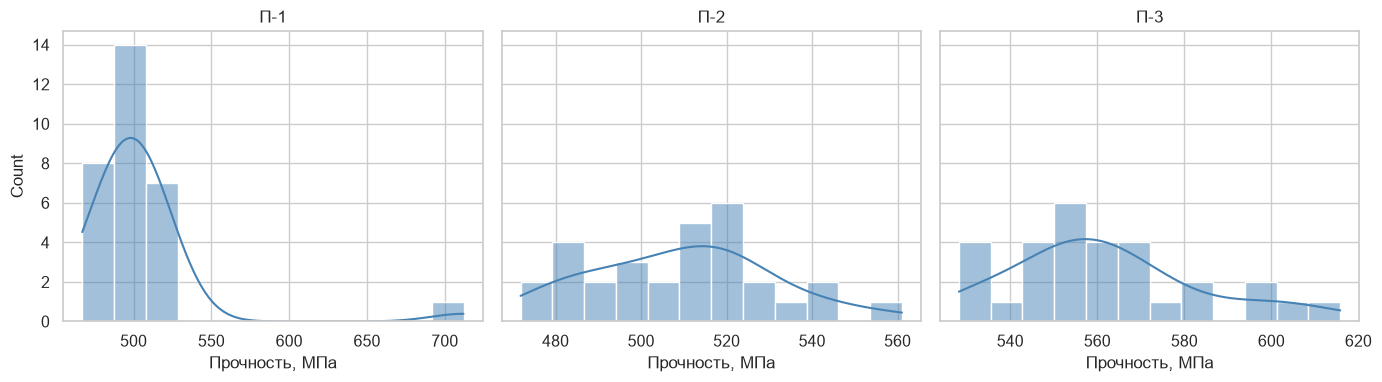

In [14]:
# plt.subplots(1, 3) создаёт рисунок fig из 1 строки и 3 графиков axes (по одному на партию)
# sharey=True — общая шкала по вертикали, чтобы графики было честно сравнивать
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

# цикл по партиям: groupby выдаёт пары (название партии, её строки), zip ставит каждой партии свой график
for ax, (партия, группа) in zip(axes, данные.groupby('партия')):
    # гистограмма: bins — число столбиков, kde=True добавляет сглаженную кривую плотности
    sns.histplot(группа['прочность'], bins=12, kde=True, ax=ax, color='steelblue')
    ax.set_title(партия)
    ax.set_xlabel('Прочность, МПа')

plt.tight_layout()  # аккуратно раздвинуть графики, чтобы подписи не налезали
plt.show()

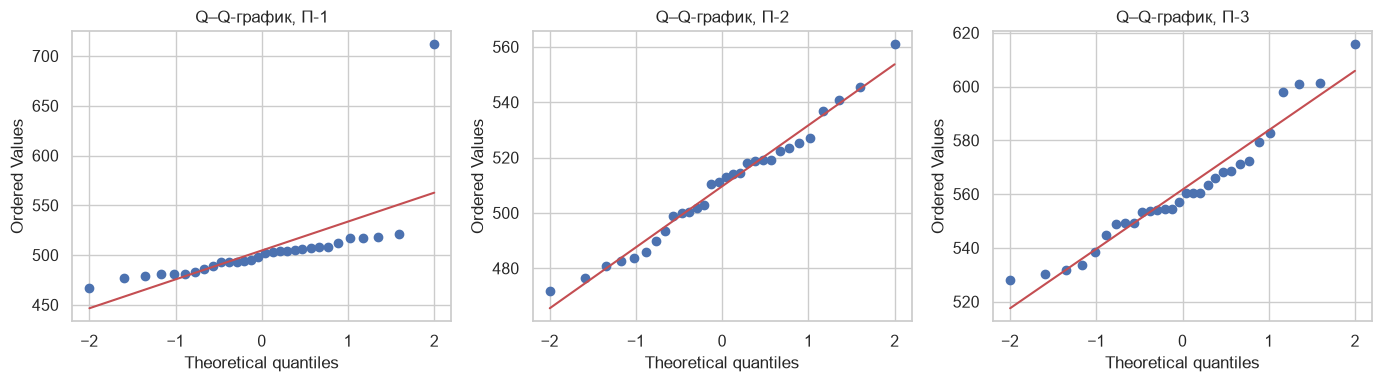

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (партия, группа) in zip(axes, данные.groupby('партия')):
    # stats.probplot строит Q–Q-график: по горизонтали — где точка была бы при нормальном распределении,
    # по вертикали — где она на самом деле; dropna() убирает пропуски, dist='norm' — сравниваем с нормальным
    stats.probplot(группа['прочность'].dropna(), dist='norm', plot=ax)
    ax.set_title(f'Q–Q-график, {партия}')  # f-строка: {партия} подставит название партии

plt.tight_layout()
plt.show()

In [16]:
строки = []  # сюда будем складывать результаты по каждой партии

for партия, группа in данные.groupby('партия'):
    x = группа['прочность'].dropna()  # прочность одной партии без пропусков

    # критерий Шапиро–Уилка возвращает два числа: статистику W (чем ближе к 1, тем «нормальнее») и p-значение
    W, p = stats.shapiro(x)

    # словарь {'имя столбца': значение} — одна будущая строка таблицы
    строки.append({
        'партия': партия,
        'n': len(x),
        'асимметрия': x.skew(),   # skew: 0 — симметрично, > 0 — длинный хвост вправо
        'эксцесс': x.kurt(),      # kurt: 0 — как у нормального, > 0 — острая вершина и тяжёлые хвосты
        'W Шапиро': W,
        'p': p,
        'нормальное?': 'да' if p >= 0.05 else 'нет',  # если p ≥ 0,05, нормальность не отвергаем
    })

# из списка словарей делаем таблицу, партию ставим в заголовки строк
нормальность = pd.DataFrame(строки).set_index('партия')
нормальность.round(3)  # округлить до 3 знаков для показа

,n,асимметрия,эксцесс,W Шапиро,p,нормальное?
партия,,,,,,
П-1,30,4.53,23.10,0.49,0.00,нет
П-2,30,0.26,-0.14,0.98,0.80,да
П-3,30,0.72,0.31,0.94,0.11,да


**Что мы видим.**

- **П-2.** Гистограмма симметричная, точки на Q–Q-графике лежат на линии, асимметрия и эксцесс около 0, p ≈ 0,80. Данные похожи на нормальные.
- **П-3.** p ≈ 0,11, это больше 0,05, значит нормальность не нарушена. Справа есть небольшой «хвост»: на Q–Q-графике одна точка чуть выше линии. Запомним её.
- **П-1.** p очень маленькое (примерно 0,000000004), асимметрия около 4,5, эксцесс около 23. На гистограмме видно, что почти все значения образуют аккуратную гору, а **одна точка улетела к 700 МПа**. На Q–Q-графике она стоит отдельно в правом верхнем углу.

**Осторожно с p.** Если p больше 0,05, это не доказательство нормальности. Это значит лишь, что проверка не нашла отличий. Когда образцов мало (меньше 20), проверка слабая и многое пропускает. Когда образцов очень много (больше 1000), она придирается даже к мелочам. Поэтому смотрите **и на графики, и на p вместе**.

### Почему нельзя проверять все партии сразу

Посмотрим, что будет, если смешать все партии вместе. Ошибочное значение 712 МПа для этого уберём.

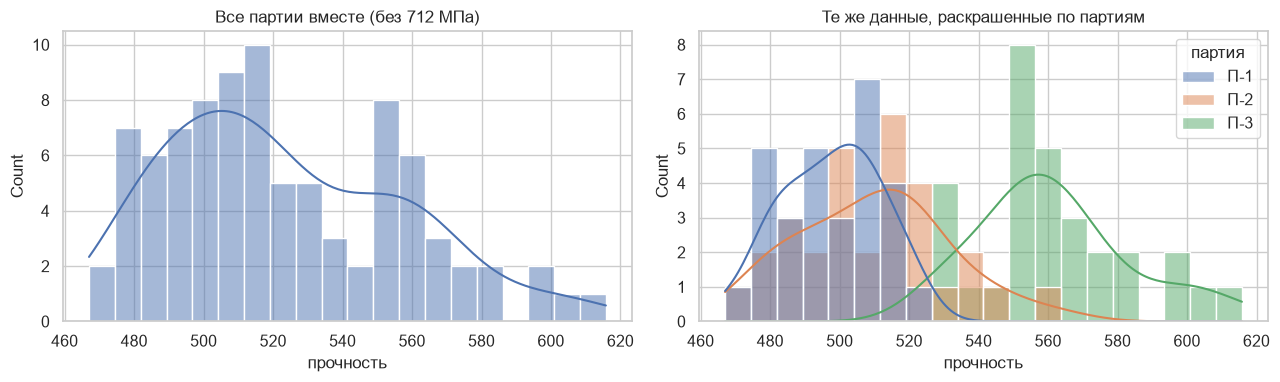

Шапиро–Уилк по всем партиям вместе: p = 0.004


In [17]:
# временно уберём очень большое значение 712 МПа, чтобы оно не мешало смотреть на форму
без_выброса = данные[данные['прочность'] < 650]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# слева: все партии одной кучей
sns.histplot(без_выброса['прочность'], bins=20, kde=True, ax=axes[0])
axes[0].set_title('Все партии вместе (без 712 МПа)')

# справа: те же данные, но hue='партия' раскрашивает каждую партию своим цветом
sns.histplot(data=без_выброса, x='прочность', hue='партия', bins=20, kde=True, ax=axes[1])
axes[1].set_title('Те же данные, раскрашенные по партиям')

plt.tight_layout()
plt.show()

# .pvalue берёт из результата критерия только p-значение, round(..., 4) округляет до 4 знаков
print('Шапиро–Уилк по всем партиям вместе: p =', round(stats.shapiro(без_выброса['прочность']).pvalue, 4))

Даже без ошибочного значения смесь трёх партий **не нормальная** (p ≈ 0,004). При этом каждая партия по отдельности нормальная.

На правом графике понятно почему. П-1 и П-2 образуют одну гору около 500–510 МПа, а П-3 стоит отдельной горой около 560. Если сложить две горы, получится кривая с «плечом», а не одна ровная гора.

**Вывод.** Если все данные вместе не нормальные, это часто значит, что в них перемешаны разные группы. Сначала разделите данные на группы, а потом проверяйте форму.

## 5. Выбросы: как найти и что с ними делать

**Выброс** это значение, которое сильно отличается от остальных. Бывает две причины:

1. **Ошибка.** Опечатались при записи (712 вместо 512), прибор дал сбой, перепутали образцы.
2. **Настоящее редкое значение.** Образец действительно получился необычным.

Компьютер умеет только **найти подозрительные значения**. Решить, ошибка это или нет, может только человек, который понимает, что измеряли, и может проверить записи.

### Три способа найти подозрительные значения

| Способ | Правило простыми словами | Особенность |
|---|---|---|
| Правило IQR | значение сильно ниже нижней четверти или сильно выше верхней четверти (дальше, чем полтора межквартильных размаха) | сам выброс на границы не влияет |
| z-оценка | значение отстоит от среднего больше чем на 3 стандартных отклонения | выброс сам раздувает стандартное отклонение и может «спрятаться» |
| Робастная z-оценка | то же, но считают от медианы, а не от среднего (граница 3,5) | выбросы на неё почти не влияют |

Сначала посмотрим глазами на **ящик с усами**. Ящик показывает, где лежит средняя половина образцов, линия внутри ящика это медиана. «Усы» тянутся к обычным значениям. Всё, что дальше усов, рисуется отдельными точками.

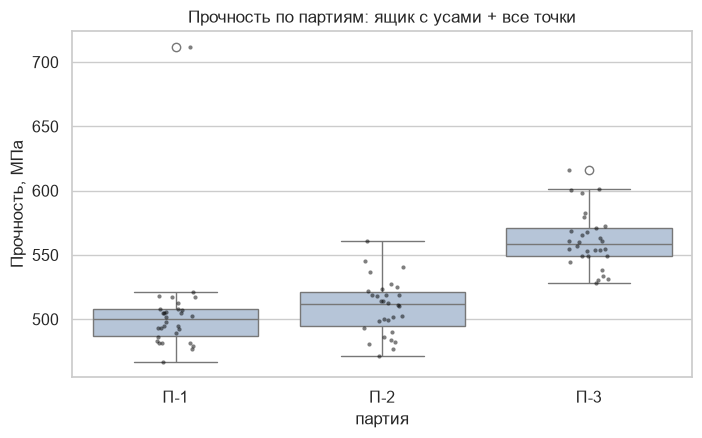

In [18]:
plt.figure(figsize=(8, 4.5))

# ящик с усами: линия внутри ящика — медиана, края ящика — Q1 и Q3,
# усы тянутся до самых дальних точек в пределах 1,5·IQR, всё, что дальше, рисуется отдельными точками
sns.boxplot(data=данные, x='партия', y='прочность', color='lightsteelblue')

# поверх рисуем все наблюдения точками; alpha=0.5 — полупрозрачность, чтобы видеть наложения
sns.stripplot(data=данные, x='партия', y='прочность', color='black', size=3, alpha=0.5)

plt.ylabel('Прочность, МПа')
plt.title('Прочность по партиям: ящик с усами + все точки')
plt.show()

За усами две точки: 712 МПа в П-1 (очень далеко) и около 616 МПа в П-3 (рядом с усом). Найдём подозрительные значения всеми тремя способами. Границы считаем **для каждой партии отдельно**, потому что прочность у партий разная.

In [19]:
# функция получает столбец чисел x и для каждого значения отвечает: выброс или нет по трём правилам
def найти_выбросы(x):
    # правило IQR (Тьюки): границы Q1 − 1,5·IQR и Q3 + 1,5·IQR
    q1, q3 = x.quantile([0.25, 0.75])
    размах = q3 - q1

    # обычная z-оценка: на сколько стандартных отклонений значение отстоит от среднего
    z = (x - x.mean()) / x.std()

    # робастная z-оценка: то же, но от медианы и через MAD (медианное абсолютное отклонение)
    # scale='normal' уже домножает MAD на 1,4826, чтобы его можно было сравнивать со std
    mad = stats.median_abs_deviation(x, scale='normal')
    z_робаст = (x - x.median()) / mad

    # собираем таблицу: True — правило считает значение выбросом
    # знак | означает «или», .abs() — модуль числа
    return pd.DataFrame({
        'значение': x,
        'IQR': (x < q1 - 1.5 * размах) | (x > q3 + 1.5 * размах),
        'z>3': z.abs() > 3,
        'робаст_z>3.5': z_робаст.abs() > 3.5,
        'z': z.round(2),
        'робаст_z': z_робаст.round(2),
    })


# .apply(функция) применяет нашу функцию к каждой партии отдельно — границы у каждой партии свои
проверка = данные.groupby('партия')['прочность'].apply(найти_выбросы)

# оставляем только строки, где хотя бы одно из трёх правил сказало True
кандидаты = проверка[проверка[['IQR', 'z>3', 'робаст_z>3.5']].any(axis=1)]
кандидаты

,,значение,IQR,z>3,робаст_z>3.5,z,робаст_z
партия,,,,,,,
П-1,20,712.0,True,True,True,4.99,15.13
П-3,68,615.8,True,False,True,2.48,3.91


**Разберём каждое подозрительное значение.**

**712 МПа в П-1.** Его отметили все три способа. Значение больше среднего партии на 5 стандартных отклонений и почти на 200 МПа больше соседей. При этом твёрдость (187,6) и углерод (0,243 %) у этого образца самые обычные для партии. Если бы прочность правда была 712 МПа, твёрдость тоже была бы выше: эти свойства растут вместе. Скорее всего, это опечатка, например 712 вместо 512. **Решение: это ошибка, исключаем образец из анализа.** В отчёте обязательно пишем, что исключили и почему.

**Около 616 МПа в П-3.** Правило IQR и робастная z-оценка его отметили, а обычная z-оценка нет (z ≈ 2,5, меньше 3). Значение лишь немного выходит за ус. Твёрдость у этого образца тоже высокая (215,7, больше, чем у трёх четвертей образцов партии), и углерод выше среднего по партии. То есть все свойства образца согласуются друг с другом. **Решение: это настоящее значение, оставляем.**

**Главное правило:** не удаляйте всё подряд, что нашёл компьютер. Правило IQR иногда отмечает и совершенно нормальные значения. Если удалить их все, данные станут «красивее», чем они есть на самом деле, а это обман.

Проверим, что у образца с 712 МПа остальные свойства обычные.

In [20]:
# берём только партию П-1 (== — проверка на равенство), три столбца, считаем describe
# и через .loc[...] оставляем только строки «среднее», «минимум», «максимум»
данные[данные['партия'] == 'П-1'][['прочность', 'твёрдость', 'углерод']].describe().loc[['mean', 'min', 'max']]

,прочность,твёрдость,углерод
mean,504.65,185.88,0.22
min,467.00,171.90,0.14
max,712.00,204.30,0.26


In [21]:
# все образцы с прочностью больше 600 МПа и их остальные свойства — сравните с типичными значениями выше
данные[данные['прочность'] > 600][['образец', 'партия', 'прочность', 'твёрдость', 'углерод']]

,образец,партия,прочность,твёрдость,углерод
20,П-1-21,П-1,712.0,187.6,0.24
67,П-3-08,П-3,600.9,195.0,0.45
68,П-3-09,П-3,615.8,215.7,0.41
72,П-3-13,П-3,601.5,213.3,0.47


### Что можно сделать с выбросом

1. **Исключить**, если доказали, что это ошибка. Обязательно написать об этом в отчёте.
2. **Исправить**, если нашли правильное значение в журнале или протоколе испытаний. Это лучший вариант, но так получается не всегда.
3. **Оставить**, но описывать данные медианой и межквартильным размахом. На них выброс почти не влияет.
4. **Заменить на границу** (это называют винзоризацией). Например, всё, что больше значения, выше которого только 5 % данных, заменить на это значение. Так делают редко и осторожно.

Для 712 МПа мы выбираем первый вариант. Отметим исключённый образец специальным столбцом-флагом, чтобы всегда было видно, что именно убрали.

In [22]:
# новый столбец-флаг: True у образца П-1-21 (712 МПа, признан опечаткой), у остальных False
# исходную таблицу не портим: всегда видно, что именно и почему исключили
данные['исключён'] = данные['образец'].eq('П-1-21')

# знак ~ означает «не»: берём строки, где исключён == False; .copy() — отдельная копия таблицы
чистые = данные[~данные['исключён']].copy()

print('Было образцов:', len(данные), ' стало:', len(чистые))
print('Исключены:', данные.loc[данные['исключён'], 'образец'].tolist())  # .tolist() — превратить в обычный список

Было образцов: 90  стало: 89
Исключены: ['П-1-21']


In [23]:
# одни и те же статистики по партиям для данных до и после исключения
до = данные.groupby('партия')['прочность'].agg(['mean', 'median', 'std'])
после = чистые.groupby('партия')['прочность'].agg(['mean', 'median', 'std'])

# pd.concat с axis=1 ставит две таблицы рядом (по столбцам) под общими заголовками
pd.concat({'до удаления': до, 'после удаления': после}, axis=1).round(1)

до удаления              после удаления             
              mean median   std           mean median   std
партия                                                     
П-1          504.7  500.0  41.5          497.5  498.1  14.0
П-2          509.6  512.0  21.4          509.6  512.0  21.4
П-3          561.7  558.6  21.8          561.7  558.6  21.8

**Что изменилось в П-1:**

- среднее уменьшилось с 504,7 до 497,5 МПа: одно ошибочное значение сдвигало его на 7 МПа,
- медиана почти не изменилась (500,0 → 498,1): медиана выбросов не боится,
- стандартное отклонение уменьшилось втрое, с 41,5 до 14,1 МПа: одно значение давало две трети всего разброса.

У П-2 и П-3 ничего не изменилось, их мы не трогали. Ещё раз проверим, нормальна ли П-1.

П-1 без выброса: n = 29, асимметрия = -0.20, эксцесс = -0.71, p Шапиро = 0.547


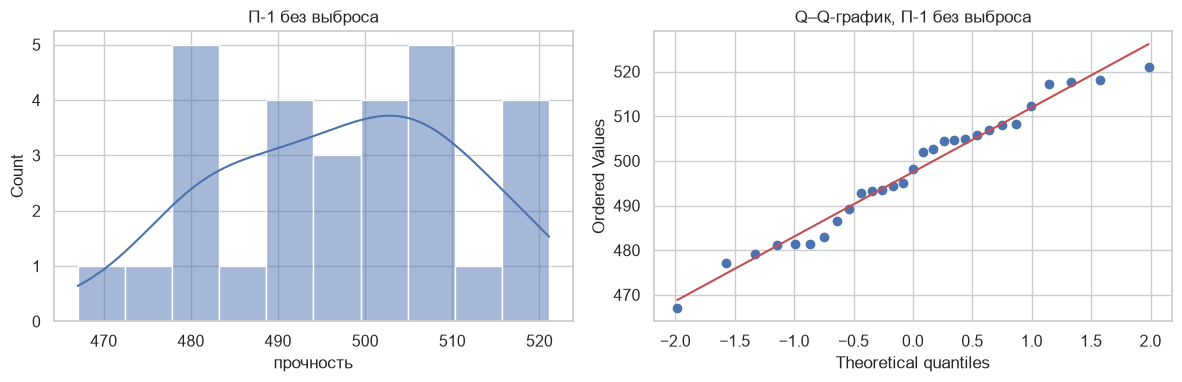

In [24]:
# .loc[условие на строки, столбец]: прочность партии П-1 после исключения выброса
x = чистые.loc[чистые['партия'] == 'П-1', 'прочность']

# в f-строке после двоеточия задаётся формат: .2f — 2 знака после запятой
print(f'П-1 без выброса: n = {len(x)}, асимметрия = {x.skew():.2f}, эксцесс = {x.kurt():.2f}, '
      f'p Шапиро = {stats.shapiro(x).pvalue:.3f}')

# слева гистограмма, справа Q–Q-график
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x, bins=10, kde=True, ax=axes[0])
axes[0].set_title('П-1 без выброса')
stats.probplot(x, dist='norm', plot=axes[1])
axes[1].set_title('Q–Q-график, П-1 без выброса')
plt.tight_layout()
plt.show()

После удаления одного ошибочного значения П-1 стала нормальной: p ≈ 0,55, точки легли на линию. То есть всю «ненормальность» создавала одна опечатка.

✏️ **Задание 2.** Найдите подозрительные значения **твёрдости** с помощью функции `найти_выбросы`. Если нашли, посмотрите на прочность и углерод этих образцов и решите, ошибка это или настоящее значение.

In [25]:
# dropna(): медианное абсолютное отклонение не умеет пропускать пропуски, как mean/std
проверка_твёрдости = чистые.groupby('партия')['твёрдость'].apply(
    lambda x: найти_выбросы(x.dropna())
)
кандидаты_твёрдости = проверка_твёрдости[
    проверка_твёрдости[['IQR', 'z>3', 'робаст_z>3.5']].any(axis=1)
]
print(кандидаты_твёрдости)

# посмотрим остальные свойства этих образцов
номера = [индекс[1] for индекс in кандидаты_твёрдости.index]
чистые.loc[номера, ['образец', 'партия', 'прочность', 'твёрдость', 'углерод']]

           значение   IQR    z>3  робаст_z>3.5     z  робаст_z
партия                                                        
П-2    42     209.2  True  False         False  2.42      2.72
П-3    63     223.8  True  False         False  2.12      3.49
       71     189.3  True  False         False -1.70     -3.26
       83     181.9  True  False          True -2.52     -4.70
       88     189.2  True  False         False -1.71     -3.27


,образец,партия,прочность,твёрдость,углерод
42,П-2-13,П-2,518.7,209.2,0.24
63,П-3-04,П-3,531.7,223.8,0.36
71,П-3-12,П-3,568.7,189.3,0.40
83,П-3-24,П-3,554.6,181.9,0.42
88,П-3-29,П-3,553.9,189.2,0.32



**Ответ.** IQR отметил 5 значений: П-2-13 (209,2), П-3-04 (223,8), П-3-12 (189,3), П-3-24 (181,9), П-3-29 (189,2). Ни одно не похоже на опечатку: все лежат в пределах 182–224 HB, это обычный разброс твёрдости. Обычная z-оценка не отметила ни одного (|z| ≈ 1,7–2,5), робастная — только П-3-24 (−4,7).

Свойства согласованы: у П-3-04 высокая и твёрдость, и прочность, и углерод. У образцов с низкой твёрдостью (П-3-12, П-3-24, П-3-29) прочность обычная для П-3 (555–569 МПа), а внутри П-3 связь прочности с твёрдостью почти отсутствует (см. задание 3), значит противоречия нет. **Решение: оставляем все пять значений.** Единственная настоящая ошибка в этих данных — 712 МПа, она уже исключена.

**Заодно исправление:** функция `найти_выбросы` считает `median_abs_deviation`, который не пропускает `NaN`, поэтому при применении к столбцам с пропусками мы передаём в неё `x.dropna()`. Иначе робастная z-оценка была бы `NaN` для всей партии.


## 6. Графики: какой график для какого вопроса

| Вопрос | Какой график | Команда seaborn |
|---|---|---|
| Как распределены значения одного признака? | гистограмма, сглаженная кривая | `histplot`, `kdeplot` |
| Похоже ли на нормальное распределение? | Q–Q-график | `scipy.stats.probplot` |
| Чем отличаются группы? | ящик с усами, «скрипка», точки | `boxplot`, `violinplot`, `stripplot` |
| Связаны ли два признака? | точечная диаграмма | `scatterplot`, `regplot` |
| Как связаны все признаки сразу? | все пары признаков, цветная таблица связей | `pairplot`, `heatmap` |

### 6.1. Сравниваем группы

«Скрипка» показывает форму распределения целиком: где она шире, там больше образцов. Ящик с усами показывает медиану и четверти. Точки показывают сами образцы. **Хорошая привычка: всегда рисуйте точки**, если их не слишком много. Так видно, сколько данных стоит за картинкой.

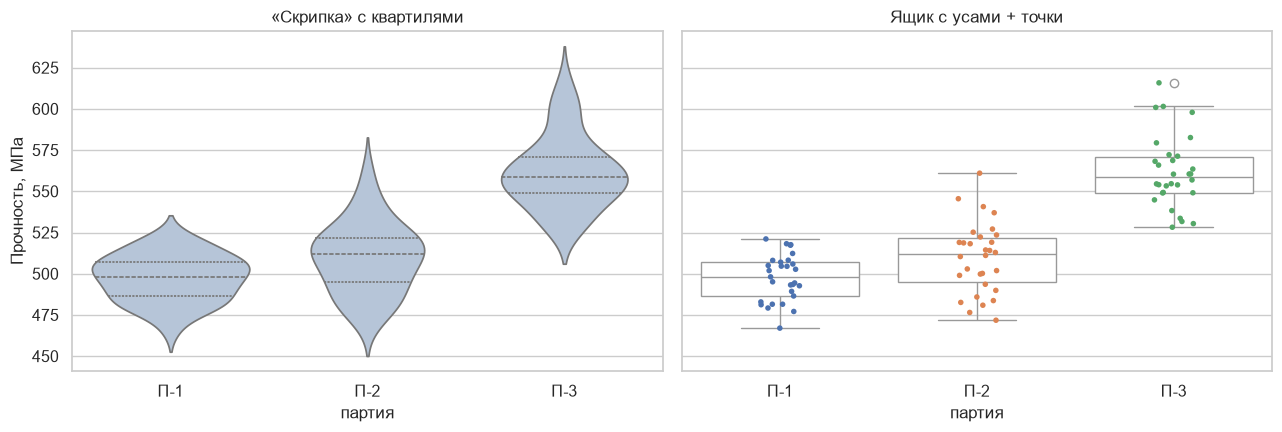

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

# «скрипка»: ширина фигуры показывает, сколько значений на этом уровне;
# inner='quartile' рисует внутри пунктиром медиану и квартили
sns.violinplot(data=чистые, x='партия', y='прочность', inner='quartile', color='lightsteelblue', ax=axes[0])
axes[0].set_title('«Скрипка» с квартилями')

# ящик с усами и все точки, раскрашенные по партиям (legend=False — без лишней легенды)
sns.boxplot(data=чистые, x='партия', y='прочность', color='white', ax=axes[1])
sns.stripplot(data=чистые, x='партия', y='прочность', hue='партия', legend=False, size=4, ax=axes[1])
axes[1].set_title('Ящик с усами + точки')

for ax in axes:
    ax.set_ylabel('Прочность, МПа')  # подпись оси с единицами измерения на обоих графиках

plt.tight_layout()
plt.show()

### 6.2. Связаны ли два признака

Главный вопрос для металлурга: как прочность зависит от углерода? Нарисуем точки и посчитаем **коэффициент корреляции**. Это число от −1 до 1, которое показывает, насколько согласованно меняются два признака:

- около 1: один растёт, и другой растёт,
- около −1: один растёт, а другой падает,
- около 0: связи нет.

Есть два вида корреляции:

- **Пирсона (r)** ищет связь по прямой линии и боится выбросов,
- **Спирмена (ρ)** смотрит только на порядок значений («больше» или «меньше») и выбросов не боится.

Все партии вместе: Пирсон r = 0.81 (p = 2e-21), Спирмен ρ = 0.79 (p = 6e-20)


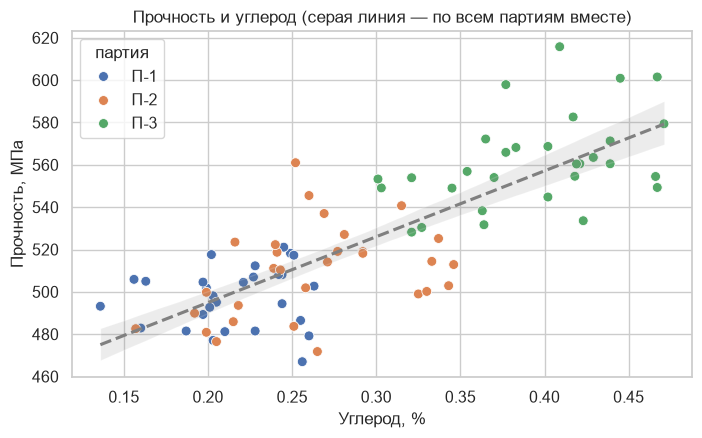

In [27]:
# для корреляции нужны пары значений, поэтому убираем строки, где пропущен хотя бы один из двух признаков
пара = чистые[['углерод', 'прочность']].dropna()

# каждая функция возвращает коэффициент и p-значение (проверка гипотезы «связи нет»)
r, p_r = stats.pearsonr(пара['углерод'], пара['прочность'])       # Пирсон: линейная связь
rho, p_rho = stats.spearmanr(пара['углерод'], пара['прочность'])  # Спирмен: монотонная связь по рангам
# формат .1g — короткая запись очень маленьких чисел, например 2e-21 = 2·10⁻²¹
print(f'Все партии вместе: Пирсон r = {r:.2f} (p = {p_r:.1g}), Спирмен ρ = {rho:.2f} (p = {p_rho:.1g})')

# диаграмма рассеяния: каждая точка — образец, цвет — партия, s — размер точек
sns.scatterplot(data=чистые, x='углерод', y='прочность', hue='партия', s=50)

# линия регрессии по всем данным сразу; scatter=False — точки второй раз не рисовать, ls='--' — пунктир
sns.regplot(data=чистые, x='углерод', y='прочность', scatter=False, color='gray', line_kws={'ls': '--'})

plt.xlabel('Углерод, %')
plt.ylabel('Прочность, МПа')
plt.title('Прочность и углерод (серая линия — по всем партиям вместе)')
plt.show()

По всем образцам связь сильная: r ≈ 0,81. Но посмотрите на цвета: партии лежат отдельными «облаками» в разных местах графика. Посчитаем корреляцию **внутри** каждой партии.

П-1: r = 0.10, p = 0.617, n = 28
П-2: r = 0.37, p = 0.043, n = 30
П-3: r = 0.44, p = 0.015, n = 30


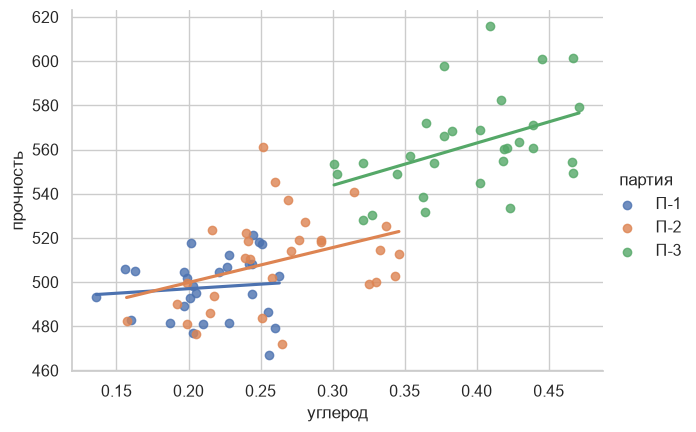

In [28]:
# та же корреляция Пирсона, но отдельно внутри каждой партии
for партия, группа in чистые.groupby('партия'):
    п = группа[['углерод', 'прочность']].dropna()
    r, p = stats.pearsonr(п['углерод'], п['прочность'])
    print(f'{партия}: r = {r:.2f}, p = {p:.3f}, n = {len(п)}')

# lmplot рисует точки и свою линию регрессии для каждой партии (hue)
# height и aspect — высота и отношение ширины к высоте, ci=None — без полосы доверительного интервала
sns.lmplot(data=чистые, x='углерод', y='прочность', hue='партия', height=4.5, aspect=1.4, ci=None)
plt.show()

**Что мы видим.** Внутри партий связь гораздо слабее (r от 0,1 до 0,44), чем по всем образцам вместе (0,81). Почему так? П-3 одновременно и с большим количеством углерода, и прочнее остальных. Поэтому общее «r = 0,81» в основном говорит о том, что **партии отличаются друг от друга**, а не о том, как углерод влияет на прочность внутри одной плавки.

Оба числа правильные, но отвечают на разные вопросы. Когда пишете вывод, указывайте, по каким данным посчитана связь: по всем вместе или внутри групп.

### 6.3. Все признаки сразу

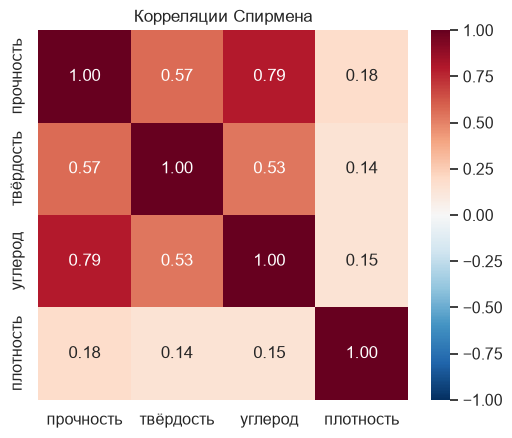

In [29]:
признаки = ['прочность', 'твёрдость', 'углерод', 'плотность']  # список числовых столбцов, понадобится ещё не раз

plt.figure(figsize=(6, 4.8))

# .corr(method='spearman') — таблица корреляций каждой пары признаков
# heatmap раскрашивает её: annot=True — подписать числа, fmt='.2f' — 2 знака,
# cmap='RdBu_r' — красный для положительных, синий для отрицательных, vmin/vmax — шкала от −1 до 1
sns.heatmap(чистые[признаки].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Корреляции Спирмена')
plt.show()

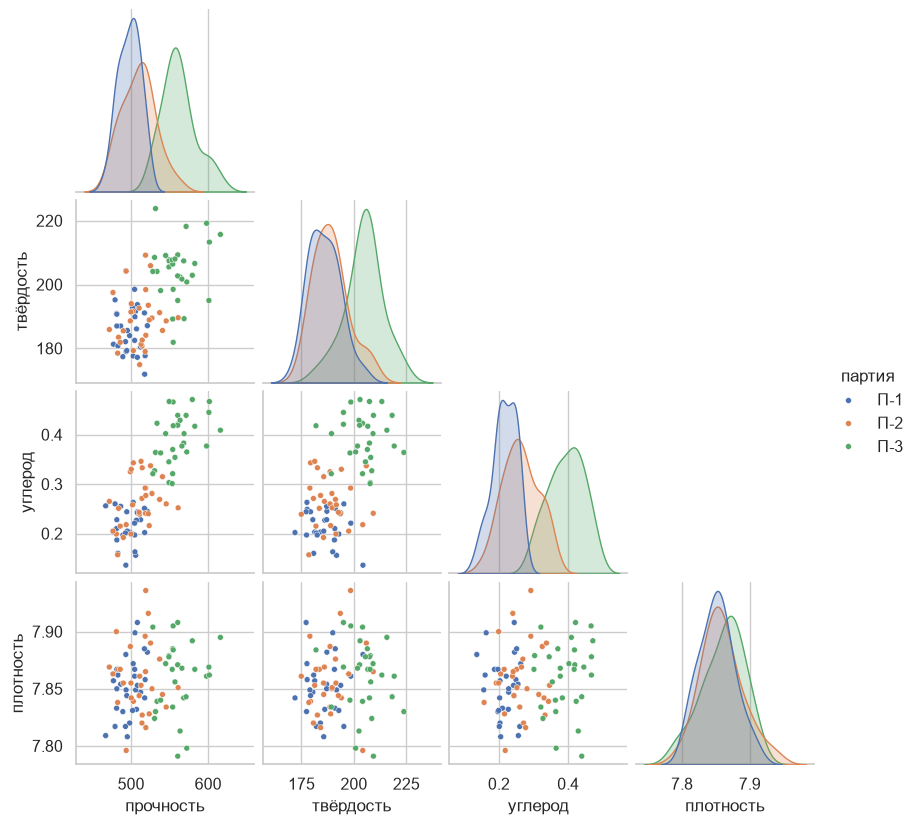

In [30]:
# pairplot строит диаграммы рассеяния для всех пар признаков, на диагонали — распределение каждого признака
# corner=True — только нижний треугольник (верхний повторял бы его зеркально)
sns.pairplot(чистые, vars=признаки, hue='партия', corner=True, height=2.1, plot_kws={'s': 18})
plt.show()

Прочность, твёрдость и углерод растут вместе. Плотность почти ни с чем не связана. На большом графике снова видно, что П-3 стоит отдельно.

**Каким должен быть хороший график:**

- подписаны оси и указаны единицы измерения (МПа, %, HB),
- есть заголовок,
- цвет что-то означает, и одна партия везде одного цвета,
- нет лишних украшений (объёма, теней),
- ось не обрезана так, чтобы маленькая разница выглядела огромной.

✏️ **Задание 3.** Нарисуйте точечную диаграмму: по горизонтали прочность, по вертикали твёрдость, цвет по партиям. Посчитайте корреляцию Спирмена внутри каждой партии.

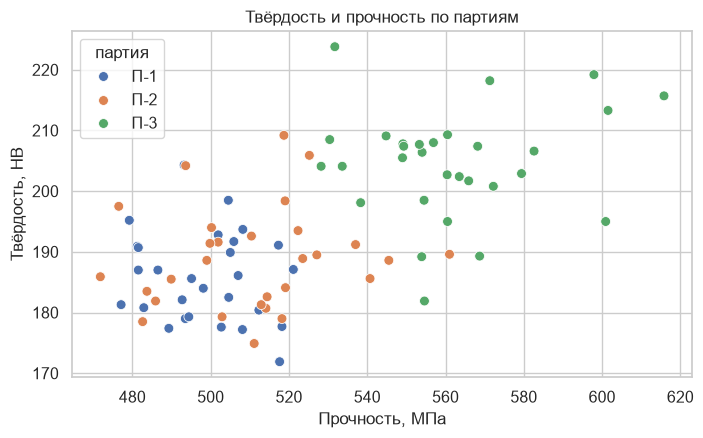

По всем образцам вместе: ρ = 0.57, p = 8.69e-09
П-1: ρ = -0.14, p = 0.49, n = 28
П-2: ρ = 0.17, p = 0.38, n = 29
П-3: ρ = 0.01, p = 0.95, n = 30


In [31]:
sns.scatterplot(data=чистые, x='прочность', y='твёрдость', hue='партия', s=50)
plt.xlabel('Прочность, МПа')
plt.ylabel('Твёрдость, HB')
plt.title('Твёрдость и прочность по партиям')
plt.show()

пара_все = чистые[['прочность', 'твёрдость']].dropna()
rho, p = stats.spearmanr(пара_все['прочность'], пара_все['твёрдость'])
print(f'По всем образцам вместе: ρ = {rho:.2f}, p = {p:.3g}')

for партия, группа in чистые.groupby('партия'):
    пара = группа[['прочность', 'твёрдость']].dropna()
    rho, p = stats.spearmanr(пара['прочность'], пара['твёрдость'])
    print(f'{партия}: ρ = {rho:.2f}, p = {p:.2f}, n = {len(пара)}')


По всем образцам вместе связь умеренная: ρ Спирмена = 0,57 (p < 0,001). Но на графике видно три отдельные «облака» — партии лежат в разных местах. Внутри партий связи практически нет: П-1 ρ = −0,14 (p = 0,49), П-2 ρ = 0,17 (p = 0,38), П-3 ρ = 0,01 (p = 0,95). Ни один коэффициент не значим.

Это тот же эффект, что и с углеродом: общая связь возникает из-за того, что П-3 одновременно и прочнее, и твёрже остальных. Внутри одной плавки прочность и твёрдость почти не связаны, то есть измерить одно по другому нельзя. В выводе обязательно нужно указать, по каким данным посчитана связь.


## 7. Какие группы сравнивать

Образцы можно разбить на группы двумя способами: **по партиям** или **по поставщикам**. Какой правильный? Посчитаем оба.

In [32]:
# группировка по одному столбцу — по поставщику
по_поставщикам = чистые.groupby('поставщик')['прочность'].agg(['count', 'mean', 'median', 'std'])

# группировка по двум столбцам сразу — каждая партия внутри своего поставщика
по_партиям = чистые.groupby(['поставщик', 'партия'])['прочность'].agg(['count', 'mean', 'median', 'std'])

# display показывает таблицу красиво, как последняя строка ячейки; нужен, чтобы вывести две таблицы подряд
display(по_поставщикам.round(1))
display(по_партиям.round(1))

,count,mean,median,std
поставщик,,,,
Магнитогорский металлургический комбинат,59,530.1,528.2,37.2
Северсталь,30,509.6,512.0,21.4


count   mean  median   std
поставщик                                партия                            
Магнитогорский металлургический комбинат П-1        29  497.5   498.1  14.0
                                         П-3        30  561.7   558.6  21.8
Северсталь                               П-2        30  509.6   512.0  21.4

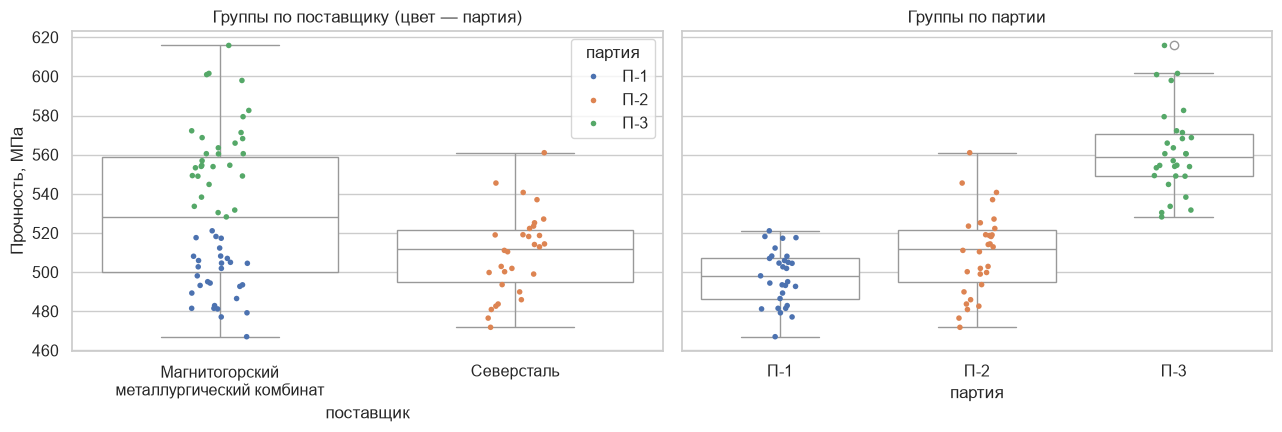

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

# слева группы по поставщику, но точки раскрашены по партии — так видно, из чего состоит группа
sns.boxplot(data=чистые, x='поставщик', y='прочность', color='white', ax=axes[0])
sns.stripplot(data=чистые, x='поставщик', y='прочность', hue='партия', size=4, ax=axes[0])
axes[0].set_title('Группы по поставщику (цвет — партия)')
axes[0].set_xticks(axes[0].get_xticks(), [т.get_text().replace(' металлургический', '\nметаллургический')
                                          for т in axes[0].get_xticklabels()])  # длинное название — на две строки

# справа группы по партии
sns.boxplot(data=чистые, x='партия', y='прочность', color='white', ax=axes[1])
sns.stripplot(data=чистые, x='партия', y='прочность', hue='партия', legend=False, size=4, ax=axes[1])
axes[1].set_title('Группы по партии')
axes[0].set_ylabel('Прочность, МПа')

plt.tight_layout()
plt.show()

**Разбираемся.**

У Магнитогорского металлургического комбината две партии, П-1 и П-3. Они очень разные: около 498 и около 562 МПа. Если сложить их в одну группу, получится:

- среднее около 530 МПа, которого **нет ни в одной настоящей партии**,
- большой разброс, который появился не сам по себе, а потому что смешали две разные плавки,
- две горы на гистограмме, то есть не нормальное распределение.

Сравнивать так Магнитогорский металлургический комбинат с «Северсталью» можно, но вывод будет ненадёжным. От Магнитогорского комбината у нас всего две плавки, а от «Северстали» одна. По двум плавкам нельзя судить о качестве всего завода.

**Как правильно выбрать группы.** Ответьте на пять вопросов:

1. **Что я хочу узнать?** Если хочу понять, отличаются ли плавки, группы это партии. Если хочу сравнить поставщиков, нужно много партий от каждого поставщика, а не много образцов из одной партии.
2. **Группа однородная?** Внутри группы не должно быть заметных подгрупп. Проверка: на гистограмме одна гора, а не две.
3. **Хватает ли образцов?** Для описания и проверки на нормальность нужно хотя бы 15–20 образцов в группе, лучше 30. По 5 образцам проверка почти ничего не покажет.
4. **Группы примерно одного размера?** Если в одной группе 60 образцов, а в другой 30, сравнивать их разброс сложнее.
5. **Группы придуманы заранее?** Группы задают по условиям получения образцов: партия, режим обработки, марка стали. Нельзя сначала посмотреть на прочность, разделить образцы на «прочные» и «слабые», а потом их сравнивать. Результат такого сравнения известен заранее.

В наших данных правильно сравнивать **партии**.

✏️ **Задание 4.** Разделите образцы на две группы по углероду: ниже и выше медианы. Для этого используйте `pd.qcut(чистые['углерод'], 2, labels=['низкий', 'высокий'])`. Посчитайте, сколько образцов каждой партии попало в каждую группу (`pd.crosstab`). Объясните, почему сравнение «мало углерода против много углерода» здесь почти совпадает со сравнением партий.

In [34]:
чистые['углерод_группа'] = pd.qcut(чистые['углерод'], 2, labels=['низкий', 'высокий'])
таблица = pd.crosstab(чистые['партия'], чистые['углерод_группа'])
print(таблица)
print('Медиана углерода:', round(чистые['углерод'].median(), 3))

чистые.groupby('партия')['углерод'].agg(['mean', 'median']).round(3)

углерод_группа  низкий  высокий
партия                         
П-1                 28        0
П-2                 16       14
П-3                  0       30
Медиана углерода: 0.264


,mean,median
партия,,
П-1,0.21,0.22
П-2,0.26,0.26
П-3,0.39,0.40



**Ответ.** Медиана углерода — 0,264 %. Разделение дало:

| Партия | низкий | высокий |
|---|---:|---:|
| П-1 | 28 | 0 |
| П-2 | 16 | 14 |
| П-3 | 0 | 30 |

П-1 целиком попала в «низкий углерод» (среднее около 0,21 %), П-3 целиком в «высокий» (около 0,39 %), а П-2 разделилась примерно пополам (около 0,26 %). То есть сравнение «мало углерода против много углерода» почти совпадает со сравнением партий П-1 и П-3 — это те же самые группы под другим названием.

Причина в том, что углерод и партия **перепутаны**: партии различаются по углероду сильнее, чем образцы внутри партии. Мы не можем отделить действие углерода от всех остальных различий между плавками (режим, поставщик, состав). Чтобы проверить влияние углерода, нужны образцы с разным углеродом внутри каждой партии или специально спланированный эксперимент.


## 8. Итоговая таблица для отчёта

Соберём всё в одну таблицу. Для каждой партии и каждого показателя:

- проверим нормальность (Шапиро–Уилк),
- если данные нормальные, запишем **среднее ± стандартное отклонение**,
- если нет, запишем **медиану [Q1; Q3]**.

In [35]:
# функция получает столбец чисел и возвращает готовый текст для таблицы отчёта
def описать(x):
    x = x.dropna()
    p = stats.shapiro(x).pvalue  # проверяем нормальность

    if p >= 0.05:
        # нормальное распределение → среднее ± стандартное отклонение
        # формат .3g — 3 значащие цифры, .2g — 2 значащие цифры
        return f'{x.mean():.3g} ± {x.std():.2g}'

    # не нормальное → медиана [Q1; Q3], звёздочка напоминает, что формат другой
    q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
    return f'{med:.3g} [{q1:.3g}; {q3:.3g}]*'


# применяем функцию к каждому признаку в каждой партии
итог = чистые.groupby('партия')[признаки].agg(описать)

# .insert(0, ...) вставляет первым столбцом число образцов в партии; .size() считает строки в группе
итог.insert(0, 'n', чистые.groupby('партия').size())
итог

,n,прочность,твёрдость,углерод,плотность
партия,,,,,
П-1,29,498 ± 14,186 ± 7.5,0.215 ± 0.034,7.85 ± 0.026
П-2,30,510 ± 21,189 ± 8.4,0.262 ± 0.05,7.86 ± 0.031
П-3,30,562 ± 22,205 ± 9,0.394 ± 0.05,7.86 ± 0.031


Если в таблице появится звёздочка, значит, данные не нормальные, и вместо среднего указаны медиана и квартили.

**Пример выводов для отчёта:**

> Исследовано 90 образцов стали из трёх партий. Один образец (П-1-21, прочность 712 МПа) исключён как вероятная опечатка: его прочность на 5 стандартных отклонений выше среднего по партии, а твёрдость и содержание углерода обычные. Пропуски (5 значений) не заполнялись, каждый показатель рассчитан по имеющимся данным. Во всех партиях прочность распределена нормально (критерий Шапиро–Уилка, p > 0,05), поэтому данные представлены как среднее ± стандартное отклонение. Прочность партии П-3 (около 562 ± 22 МПа) выше, чем у П-1 (около 498 ± 14 МПа) и П-2 (около 510 ± 21 МПа). В партии П-3 также больше углерода. По всем образцам прочность сильно связана с углеродом (r = 0,81), однако внутри партий связь слабая или умеренная (r = 0,10–0,44). Значит, общая связь в основном отражает различие между партиями.

Обратите внимание: пока мы только **описали** различия. Доказать, что партии действительно различаются, можно будет проверкой гипотез на следующем занятии.

## 9. Памятка: порядок работы с данными

1. Посмотреть на каждую таблицу: что в одной строке, где числа, где пропуски.
2. Проверить ключи до склеивания: не повторяются ли, одинаково ли записаны.
3. Склеить таблицы и сверить число строк до и после.
4. Считать статистику по однородным группам, а не по всем данным сразу.
5. Посмотреть на форму данных: гистограмма, Q–Q-график, проверка Шапиро–Уилка.
6. Найти подозрительные значения и разобрать каждое по смыслу. Решение записать.
7. Пересчитать статистику после решения о выбросах и сравнить «до» и «после».
8. Выбрать, как записать результат: среднее ± std или медиана [Q1; Q3].
9. Нарисовать графики под конкретные вопросы, подписать оси и единицы.
10. В выводах указывать, по каким данным посчитано: по всем вместе или по группам.

## 10. Самостоятельная работа

✏️ **Задание 5.** Повторите разделы 4–8 для **плотности**: нормальность по партиям, подозрительные значения, итоговая запись. Отличаются ли партии по плотности?

✏️ **Задание 6 (посложнее).** Загрузите файл `concrete.csv` (лежит в той же папке `1_практикум`). Это настоящие данные о прочности бетона, прочность записана в столбце `csMPa`. Найдите повторяющиеся строки. Подумайте, какие группы здесь имеет смысл сравнивать. Подсказка: прочность бетона сильно зависит от возраста `age` (в сутках), а образцов разного возраста очень разное количество (проверьте командой `value_counts`). Выберите группы, где достаточно образцов, проверьте в них нормальность прочности и опишите результат.

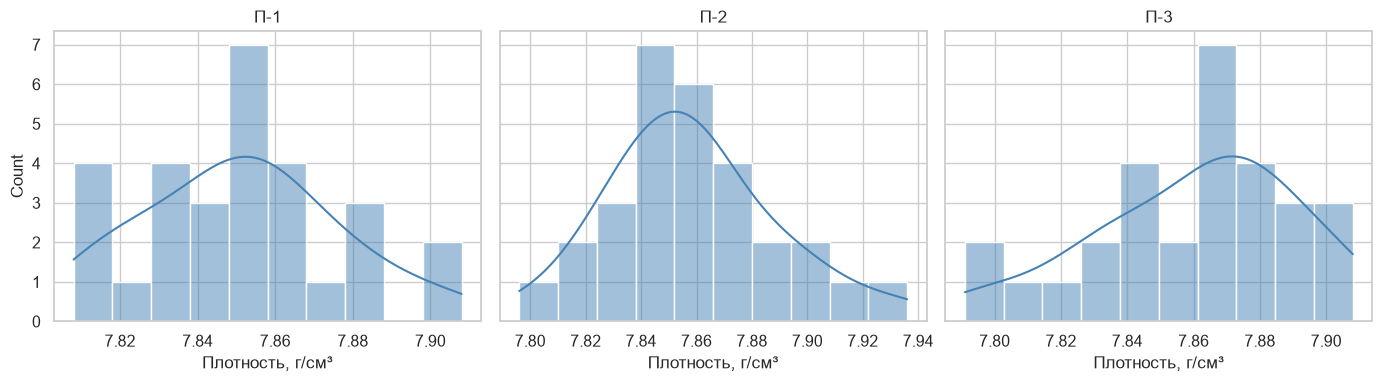

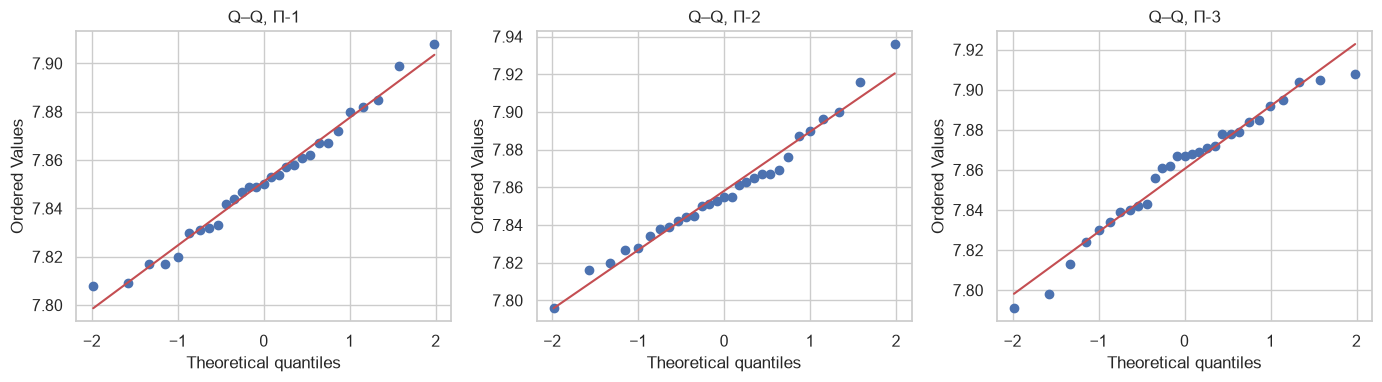

,n,асимметрия,эксцесс,W Шапиро,p,нормальное?
партия,,,,,,
П-1,29,0.25,-0.27,0.98,0.81,да
П-2,29,0.52,0.56,0.98,0.80,да
П-3,29,-0.55,-0.19,0.96,0.33,да


In [36]:
# 1) normality: гистограммы, Q–Q-графики, Шапиро–Уилк
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (партия, группа) in zip(axes, чистые.groupby('партия')):
    sns.histplot(группа['плотность'].dropna(), bins=10, kde=True, ax=ax, color='steelblue')
    ax.set_title(партия)
    ax.set_xlabel('Плотность, г/см³')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (партия, группа) in zip(axes, чистые.groupby('партия')):
    stats.probplot(группа['плотность'].dropna(), dist='norm', plot=ax)
    ax.set_title(f'Q–Q, {партия}')
plt.tight_layout()
plt.show()

строки = []
for партия, группа in чистые.groupby('партия'):
    x = группа['плотность'].dropna()
    W, p = stats.shapiro(x)
    строки.append({
        'партия': партия,
        'n': len(x),
        'асимметрия': x.skew(),
        'эксцесс': x.kurt(),
        'W Шапиро': W,
        'p': p,
        'нормальное?': 'да' if p >= 0.05 else 'нет',
    })
плотность_норм = pd.DataFrame(строки).set_index('партия')
плотность_норм.round(3)

In [37]:

# 2) подозрительные значения плотности
проверка_плотности = чистые.groupby('партия')['плотность'].apply(
    lambda x: найти_выбросы(x.dropna())
)
кандидаты_плотности = проверка_плотности[
    проверка_плотности[['IQR', 'z>3', 'робаст_z>3.5']].any(axis=1)
]
print(кандидаты_плотности)

номера = [индекс[1] for индекс in кандидаты_плотности.index]
чистые.loc[номера, ['образец', 'партия', 'плотность', 'прочность', 'твёрдость', 'углерод']]


           значение   IQR    z>3  робаст_z>3.5     z  робаст_z
партия                                                        
П-2    46      7.94  True  False         False  2.54      3.41
       47      7.92  True  False         False  1.89      2.57


,образец,партия,плотность,прочность,твёрдость,углерод
46,П-2-17,П-2,7.94,519.0,198.4,0.29
47,П-2-18,П-2,7.92,522.3,193.5,0.24


In [38]:

# 3) итоговая запись: все партии нормальные → среднее ± стандартное отклонение
итог_плотность = чистые.groupby('партия')['плотность'].agg(описать).to_frame('плотность')
итог_плотность.insert(0, 'n', чистые.groupby('партия')['плотность'].count())
итог_плотность


,n,плотность
партия,,
П-1,29,7.85 ± 0.026
П-2,29,7.86 ± 0.031
П-3,29,7.86 ± 0.031



**Ответ (задание 5).** Гистограммы и Q–Q-графики похожи на нормальные, критерий Шапиро–Уилка дал p = 0,81 (П-1), 0,80 (П-2), 0,33 (П-3) — во всех трёх партиях нормальность не нарушена. Поэтому записываем **среднее ± стандартное отклонение**: 7,85 ± 0,026; 7,86 ± 0,031; 7,86 ± 0,031 г/см³.

IQR отметил два значения в П-2 (7,936 и 7,916 г/см³), но обычная z-оценка их не отметила (2,54 и 1,89), робастная — 3,41 и 2,57. Значения физически обычные, остальные свойства этих образцов нормальные, **ошибкой их не считаем и не удаляем**.

**Партии по плотности не отличаются:** средние различаются меньше чем на 0,01 г/см³ при стандартном отклонении около 0,03. В отличие от прочности и углерода, плотность не различает плавки — этот признак не поможет отличить партию от партии.


In [39]:
бетон = pd.read_csv('concrete.csv')

print('Строк в файле:', len(бетон))
print('Точных дубликатов:', бетон.duplicated().sum())

# дубликаты — скорее всего повторная запись одного и того же результата, удаляем их
бетон = бетон.drop_duplicates().reset_index(drop=True)
print('Осталось после удаления:', len(бетон))

print('\nСколько образцов каждого возраста:')
print(бетон['age'].value_counts().sort_index())

Строк в файле: 1030
Точных дубликатов: 25
Осталось после удаления: 1005

Сколько образцов каждого возраста:
age
1        2
3      129
7      122
14      62
28     419
56      86
90      54
91      17
100     52
120      3
180     26
270     13
360      6
365     14
Name: count, dtype: int64


In [40]:

# выбираем группы, где достаточно образцов для описания и проверки нормальности
возраст_счёт = бетон['age'].value_counts()
группы = sorted(возраст_счёт[возраст_счёт >= 30].index)
print('Возраст с >= 30 образцов:', группы)

строки = []
for age in группы:
    x = бетон.loc[бетон['age'] == age, 'csMPa']
    _, p = stats.shapiro(x)
    строки.append({
        'возраст, сут': age,
        'n': len(x),
        'p Шапиро': p,
        'нормальное?': 'да' if p >= 0.05 else 'нет',
        'прочность, МПа': описать(x),
    })
итог_бетон = pd.DataFrame(строки).set_index('возраст, сут')
итог_бетон.round(3)


Возраст с >= 30 образцов: [3, 7, 14, 28, 56, 90, 100]


,n,p Шапиро,нормальное?,"прочность, МПа"
"возраст, сут",,,,
3,129,0.00e+00,нет,15.5 [11.7; 24.4]*
7,122,0.00e+00,нет,21.2 [14.5; 35.1]*
14,62,4.00e-03,нет,26.5 [22.4; 33.6]*
28,419,0.00e+00,нет,33.7 [26.2; 44.2]*
56,86,1.86e-01,да,50.7 ± 14
90,54,5.67e-01,да,40.5 ± 9.8
100,52,3.32e-01,да,47.7 ± 8.4


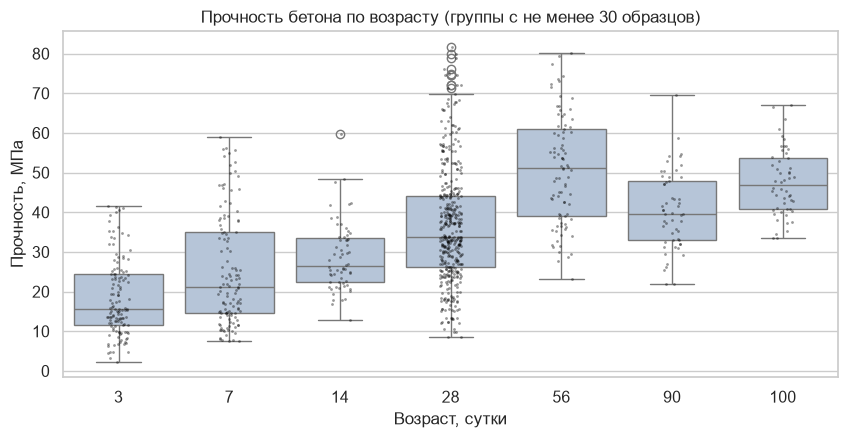

In [41]:

# ящики с усами для выбранных групп
бетон_группы = бетон[бетон['age'].isin(группы)]
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=бетон_группы, x='age', y='csMPa', color='lightsteelblue')
sns.stripplot(data=бетон_группы, x='age', y='csMPa', color='black', size=2, alpha=0.4)
plt.xlabel('Возраст, сутки')
plt.ylabel('Прочность, МПа')
plt.title('Прочность бетона по возрасту (группы с не менее 30 образцов)')
plt.show()



В `concrete.csv` 1030 строк и 25 полных дубликатов; после удаления осталось 1005 наблюдений. Имеет смысл сравнивать по возрасту `age`, но не по всем значениям подряд: возрасты 1, 91, 120, 180, 270, 360 и 365 суток содержат от 2 до 26 образцов — для проверки нормальности мало. Оставляем группы с не менее 30 образцов: **3, 7, 14, 28, 56, 90 и 100 суток**.

Нормальность прочности: в возрасте 3, 7, 14 и 28 суток p < 0,05 (данные ненормальные), в 56, 90 и 100 суток p = 0,19; 0,57 и 0,33 (нормальность не нарушена). Поэтому первые четыре группы записаны как медиана [Q1; Q3], последние три — как среднее ± стандартное отклонение (звёздочки в таблице это видно).

Прочность растёт с возрастом: медиана 15,5 → 21,2 → 26,5 → 33,7 МПа для 3–28 суток, а к 56 суткам среднее достигает 50,7 МПа. Значения для 90 и 100 суток (40,5 и 47,7 МПа) не продолжают этот рост монотонно: это разные наборы образцов, возможно с разным составом, и age 90 и 91 нельзя объединять — у 91 суток после удаления дубликатов осталось всего 17 образцов. Плюс ко всему, сравнение по возрасту здесь описательное: чтобы доказать различие групп, нужна проверка гипотез на следующем занятии.
